# ระบบอ่านตัวเลขเขียนมือบนกระดาษคำตอบจากภาพถ่าย — Demo
โน้ตบุ๊กนี้เรียงตามลำดับในสไลด์โจทย์ ทุกเซลล์เรียกฟังก์ชันจาก `t3core.py`, `common.py`, `digitnet.py`, `step5_predict.py` (ไม่มีโค้ดซ้ำในนี้)
ผลลัพธ์ที่เห็นมาจากการรันจริงบนเครื่อง (CPU) ด้วย dataset ของกลุ่ม — dataset ไม่ได้อยู่ใน repo ถ้าจะรันใหม่บน Colab ให้วางรูปที่ `data/Raw_Dataset/<0-9>/` แล้วรัน step1–step4 ก่อน

In [1]:
# ตั้งค่า (บน Colab: clone repo + ติดตั้ง lib ที่ขาด)
import sys, os
if "google.colab" in sys.modules and not os.path.exists("t3core.py"):
    !git clone -q https://github.com/67160363/handwritten-answer-sheet.git
    %cd handwritten-answer-sheet
    !pip -q install pillow-heif
import cv2, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from common import *                      # core (= t3core), path, imread, process_sheet, sheet_cells, draw_layout ...
from digitnet import DigitNet
plt.rcParams["figure.dpi"] = 110
rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

## 0) ภาพรวม pipeline
**ทำอะไร:** รับรูปถ่ายกระดาษคำตอบ Template 3 แล้วอ่านตัวเลขเขียนมือทุกช่องออกมาเป็น JSON เพื่อนำไปตรวจคะแนน
**ทำไม:** แยกเป็นขั้นตามสไลด์ (Pre-processing → ตำแหน่งตาราง → Grid Cell Segmentation → Character Check → HWR → JSON) ให้แต่ละขั้นทดสอบ/แก้ได้อิสระ
ขั้นตำแหน่งตารางในโน้ตบุ๊กนี้ใช้ **layout ที่วัดจาก template** แทน YOLO (ยังไม่ได้เทรน YOLO)

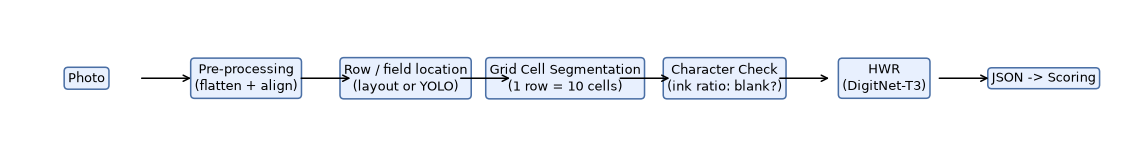

ขนาดมาตรฐานหลังจัดภาพ 1654x2339 | คลาส ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'blank'] | INK_TH = 0.04


In [2]:
steps = ["Photo", "Pre-processing\n(flatten + align)", "Row / field location\n(layout or YOLO)",
         "Grid Cell Segmentation\n(1 row = 10 cells)", "Character Check\n(ink ratio: blank?)", "HWR\n(DigitNet-T3)", "JSON -> Scoring"]
fig, ax = plt.subplots(figsize=(13, 1.6)); ax.axis("off")
for i, s in enumerate(steps):
    ax.text(i * 1.9, 0, s, ha="center", va="center", fontsize=8.5, bbox=dict(boxstyle="round", fc="#e8f0fe", ec="#4a6fa5"))
    if i: ax.annotate("", (i * 1.9 - 0.62, 0), (i * 1.9 - 1.28, 0), arrowprops=dict(arrowstyle="->"))
ax.set_xlim(-0.9, 12.3); ax.set_ylim(-1, 1); plt.show()
print(f"ขนาดมาตรฐานหลังจัดภาพ {core.STD_W}x{core.STD_H} | คลาส {CLASSES} | INK_TH = {INK_TH}")

## 1) Layout จาก template
**ทำอะไร:** วัดพิกัดแถวคำตอบ 30 แถว, ช่องรหัส 3 แถว และวงกลมฝน จาก template เปล่า (ครั้งเดียว แล้ว cache เป็น JSON)
**ทำไม:** ทุกแผ่นถูกจัดให้ตรงกับ template ก่อน จึงใช้พิกัดชุดเดียวกันตัดช่องได้ทุกแผ่น ไม่ต้อง label ตำแหน่งเอง (ใช้สร้าง label ให้ YOLO อัตโนมัติด้วย)
สีแดง = แถวคำตอบ, เขียว = ช่องรหัส, ม่วง = วงกลมชุดข้อสอบ/หน้า

page1: rows=30, header=['student_id', 'subject_id', 'school_id']
page2: rows=30, header=['student_id', 'subject_id', 'school_id']
page3: rows=30, header=['student_id', 'subject_id', 'school_id']


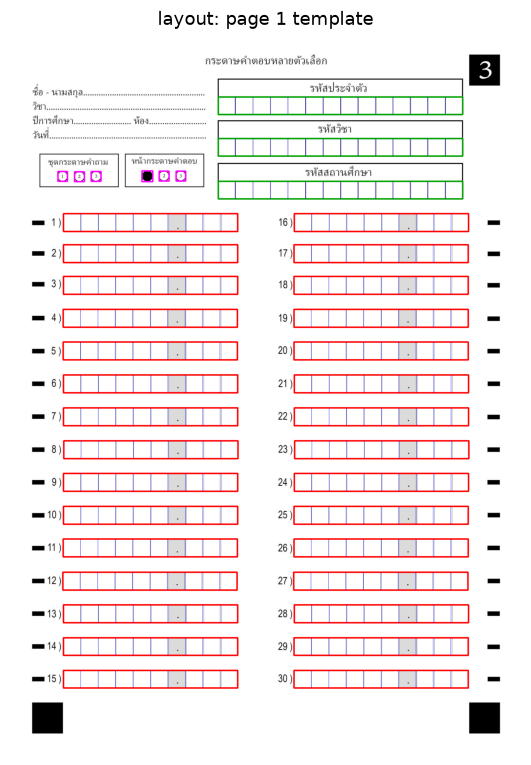

In [3]:
LAYOUT, REF = load_layouts()
tpl = core.to_std(imread(template_path(1)))
for p in LAYOUT:
    print(f"page{p}: rows={len(LAYOUT[p]['rows'])}, header={list(LAYOUT[p]['header'])}")
plt.figure(figsize=(6, 8.5)); plt.imshow(rgb(draw_layout(tpl, LAYOUT[1]))); plt.axis("off"); plt.title("layout: page 1 template"); plt.show()

## 2) จัดภาพ (Pre-processing)
**ทำอะไร:** flatten แสง → หาจุดอ้างอิง (สี่เหลี่ยมดำล่างซ้าย/ขวา, กล่องเลข 3, ขีดแถวแรก) → perspective warp เป็นขนาดมาตรฐาน; ลองหมุน 0/180/90/270
**ทำไม:** รูปถ่ายมือถือเอียง/มีเงา/ความละเอียดไม่เท่ากัน ต้องจัดให้ตรง template ก่อนตัดช่อง
`score` = ความเหมือนกับ template เฉพาะส่วนที่พิมพ์ (ปิดช่องเขียนออก) ต้อง ≥ `MIN_SCORE`

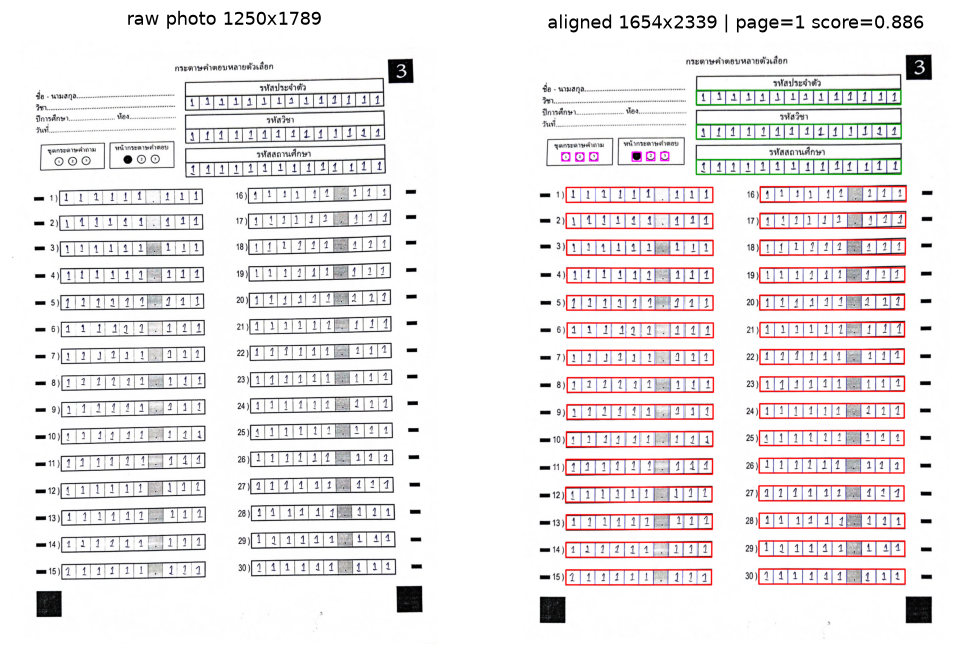

score = 0.886 (MIN_SCORE = 0.7), rot = None


In [4]:
path = os.path.join(RAW_DIR, "1", "IMG_1817.JPG")
raw = imread(path)
aligned, page, L, H, rot, score = process_sheet(path)
fig, ax = plt.subplots(1, 2, figsize=(11, 8))
ax[0].imshow(rgb(raw)); ax[0].set_title(f"raw photo {raw.shape[1]}x{raw.shape[0]}")
ax[1].imshow(rgb(draw_layout(aligned, L))); ax[1].set_title(f"aligned {aligned.shape[1]}x{aligned.shape[0]} | page={page} score={score:.3f}")
for a in ax: a.axis("off")
plt.show()
print(f"score = {score:.3f} (MIN_SCORE = {core.MIN_SCORE}), rot = {rot}")

## 3) Grid Cell Segmentation + Character Check
**ทำอะไร:** ขยับกรอบแถวให้ทับเส้นจริง (`refine_rect`) แล้วแบ่งเป็น 10 ช่องเท่ากัน (C0–C9), คำนวณ ink ratio ทุกช่อง
**ทำไม:** ช่อง index 6 (สีเทา) คือจุดทศนิยมที่พิมพ์ไว้ ข้ามเสมอ; ช่องที่ ink ratio < `INK_TH` ถือว่าว่าง ไม่ต้องส่งเข้า CNN

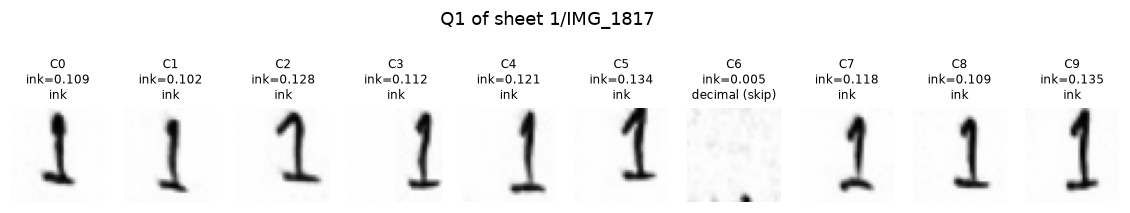

In [5]:
g = core.flatten(cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY))
cells = core.split_row(g, L["rows"][0])
fig, ax = plt.subplots(1, 10, figsize=(13, 2))
for i, (a, c) in enumerate(zip(ax, cells)):
    ink = core.ink_ratio(c)
    tag = "decimal (skip)" if i == core.DECIMAL_IDX else ("blank" if ink < INK_TH else "ink")
    a.imshow(c, cmap="gray", vmin=0, vmax=255); a.axis("off"); a.set_title(f"C{i}\nink={ink:.3f}\n{tag}", fontsize=8)
plt.suptitle("Q1 of sheet 1/IMG_1817", y=1.15); plt.show()

## 4) Dataset
**ทำอะไร:** ตัดทุกช่องของทุกแผ่น → ภาพ 32×32 (แบบ MNIST) label จากชื่อโฟลเดอร์ (แผ่นที่ทุกช่องเขียนเลขเดียวกัน) + คลาส blank
**ทำไม:** แบ่ง train/val/test **ตามแผ่น** ไม่ใช่ตามช่อง กันลายมือแผ่นเดียวกันรั่วไปอยู่ทั้ง train และ test (accuracy จะสูงเกินจริง)
ตอนนี้มีเลขละ 3 แผ่น (1/1/1) และคลาส blank มาจาก template ดิจิทัล — ยังน้อยเกินไปสำหรับรายงานผลจริง

จำนวนช่อง (split x class):


label,0,1,2,3,4,5,6,7,8,9,blank
split,,,,,,,,,,,
train,312,312,312,312,312,312,312,312,312,312,312
val,312,312,312,312,312,312,312,312,312,312,312
test,312,312,312,312,312,312,312,312,312,312,312


จำนวนแผ่นต่อ split: {'test': 11, 'train': 11, 'val': 11}


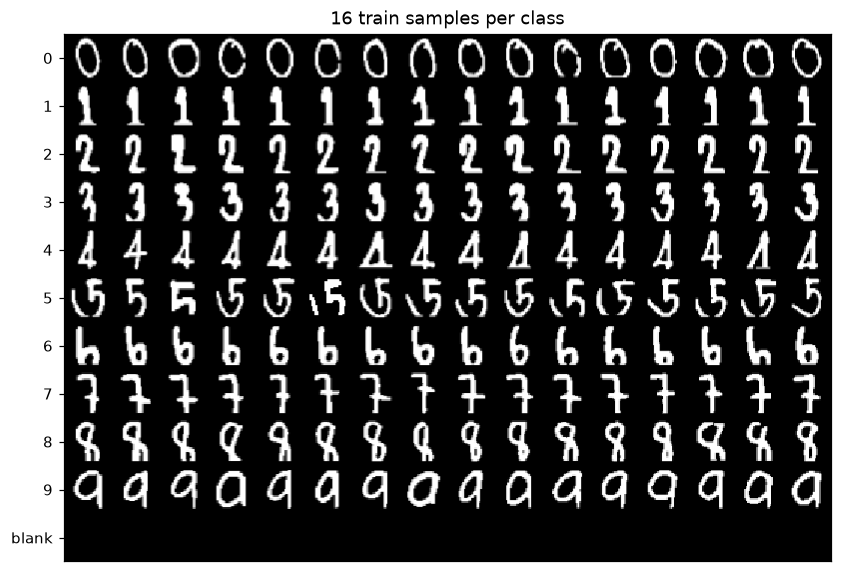

In [6]:
df = pd.read_csv(os.path.join(OUT, "cells.csv"), dtype={"label": str})
print("จำนวนช่อง (split x class):")
display(pd.crosstab(df.split, df.label).reindex(["train", "val", "test"])[CLASSES])
print("จำนวนแผ่นต่อ split:", df.groupby("split").sheet.nunique().to_dict())
plt.figure(figsize=(9, 6.5)); plt.imshow(cv2.imread(os.path.join(OUT, "cells_montage.png"), 0), cmap="gray")
plt.yticks(np.arange(11) * 48 + 24, CLASSES); plt.xticks([]); plt.title("16 train samples per class"); plt.show()

## 5) DigitNet-T3 (CNN ที่ propose)
**ทำอะไร:** 3 บล็อก [Conv-BN-ReLU ×2 + MaxPool] → Global Average Pooling → Dropout → FC 11 คลาส (0–9 + blank), input 1×32×32
**ทำไม:** งานเป็นตัวเลขเดี่ยวในช่องที่ตัดมาแล้ว โมเดลเล็ก (~0.29M params) พอ เทรนบน CPU ได้ และ pre-train ด้วย MNIST 3 epoch ก่อน fine-tune เพราะข้อมูลของเรายังน้อย

In [7]:
net = DigitNet()
print(net)
print(f"\nจำนวนพารามิเตอร์: {sum(p.numel() for p in net.parameters()):,}")

DigitNet(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=T

## 6) ผลการเทรน (test split = แผ่นที่โมเดลไม่เคยเห็น)
**ทำอะไร:** แสดง classification report, confusion matrix และกราฟ accuracy ต่อ epoch จาก `step4_train_cnn.py --epochs 15`
**ทำไม:** ดูว่าคลาสไหนอ่อน/สับสนกับคลาสไหน เพื่อตัดสินใจเก็บข้อมูลเพิ่ม — test มีเพียง 1 แผ่นต่อคลาส ตัวเลขนี้ยังใช้เทียบ baseline (CAR 98.80%) ไม่ได้

              precision    recall  f1-score   support

           0     0.9534    0.9840    0.9685       312
           1     1.0000    0.9968    0.9984       312
           2     0.9704    0.9455    0.9578       312
           3     0.9587    0.9679    0.9633       312
           4     0.9967    0.9615    0.9788       312
           5     0.8980    0.9872    0.9405       312
           6     1.0000    0.9968    0.9984       312
           7     0.9831    0.9295    0.9555       312
           8     0.9901    0.9615    0.9756       312
           9     0.9778    0.9872    0.9825       312
       blank     1.0000    1.0000    1.0000       312

    accuracy                         0.9744      3432
   macro avg     0.9753    0.9744    0.9745      3432
weighted avg     0.9753    0.9744    0.9745      3432



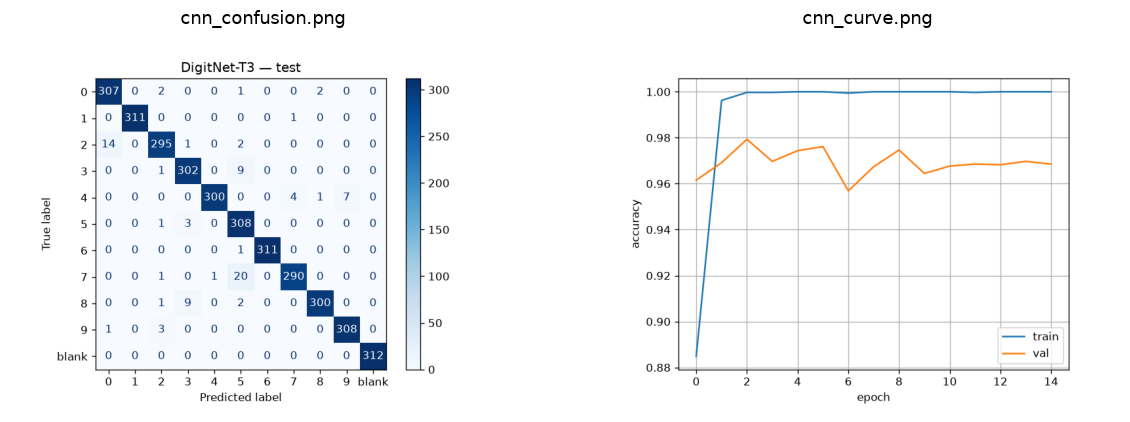

In [8]:
print(open(os.path.join(OUT, "cnn_report.txt"), encoding="utf-8").read())
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, f in zip(ax, ["cnn_confusion.png", "cnn_curve.png"]):
    a.imshow(rgb(cv2.imread(os.path.join(OUT, f)))); a.axis("off"); a.set_title(f)
plt.show()

## 7) ทำนายแผ่นจริงใน test split
**ทำอะไร:** อ่านแผ่น `7/IMG_1823` (อยู่ใน test, ไม่ได้ใช้เทรน) — จัดภาพ → ตัดช่องด้วย layout → Character Check → DigitNet → ประกอบคำตอบพร้อมจุดทศนิยม
**ทำไม:** ทดสอบ pipeline ครบวงจรแบบที่จะใช้ตรวจจริง (ใช้ `read_cells` ตัวเดียวกับ `step5_predict.py`) เลือกเลข 7 ซึ่งเป็นคลาสที่ recall ต่ำสุด เพื่อให้เห็นข้อผิดพลาดจริง

⚠ ไม่พบ YOLO best.pt — ใช้พิกัดจาก layout อย่างเดียว


ข้อ 1: 777777.757
ข้อ 2: 777777.777
ข้อ 3: 777777.777
ข้อ 4: 757777.777
ข้อ 5: 777777.777


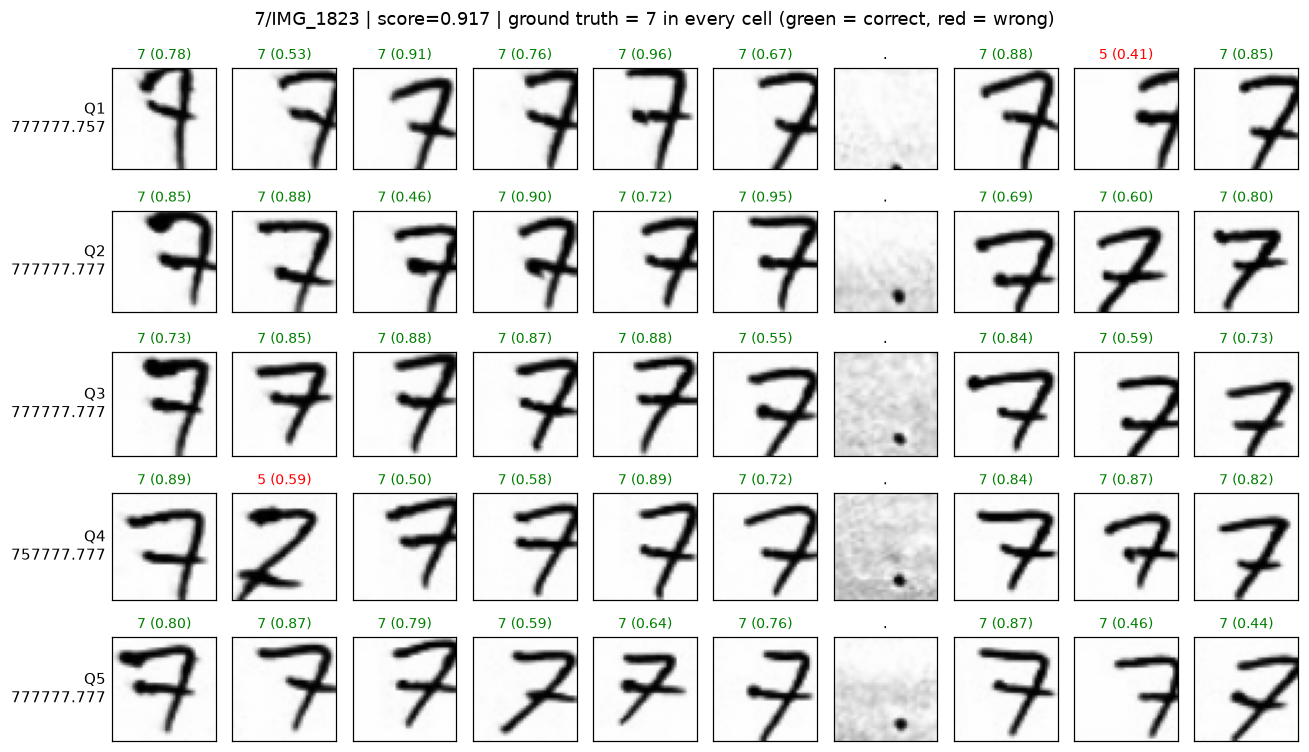

In [9]:
from step5_predict import read_cells
path = os.path.join(RAW_DIR, "7", "IMG_1823.JPG")
aligned, page, L, H, rot, score = process_sheet(path)
g = core.flatten(cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY))
fig, ax = plt.subplots(5, 10, figsize=(12, 7))
for q in range(5):
    cells = core.split_row(g, L["rows"][q])
    preds = iter(read_cells(cells[:core.DECIMAL_IDX] + cells[core.DECIMAL_IDX + 1:]))
    answer = ""
    for i, c in enumerate(cells):
        a = ax[q, i]; a.imshow(c, cmap="gray", vmin=0, vmax=255); a.set_xticks([]); a.set_yticks([])
        if i == core.DECIMAL_IDX:
            a.set_title(".", fontsize=10); answer += "."; continue
        ch, p = next(preds)
        a.set_title(f"{ch or '_'} ({p:.2f})", fontsize=9, color="green" if ch == "7" else "red")
        answer += ch
    ax[q, 0].set_ylabel(f"Q{q+1}\n{answer}", rotation=0, ha="right", va="center", fontsize=10)
    print(f"ข้อ {q+1}: {answer}")
plt.suptitle(f"7/IMG_1823 | score={score:.3f} | ground truth = 7 in every cell (green = correct, red = wrong)")
plt.tight_layout(); plt.show()